# RL-дообучение Qwen3-0.6B на задаче Countdown (GRPO + LoRA)

Трек 3 сессионного задания по обучению с подкреплением.

- Модель: `Qwen/Qwen3-0.6B` в режиме без рассуждений (`enable_thinking=False`).
- Обучение: GRPO (`trl.GRPOTrainer`) с LoRA-адаптером поверх замороженной базы.
- Задача: Countdown с программно проверяемой наградой.

Ноутбук - основной отчёт. Весь код лежит в папке `src/` и импортируется отсюда. Долгое обучение запускается
скриптом `python -m src.run_experiments`, а ноутбук только читает его логи и результаты из `results/`.
Поэтому ноутбук выполняется быстро и не требует GPU.

**Итог (подробно - раздел 11).**
- GRPO со строгой бинарной наградой поднимает строгую точность на held-out с 20.3% до 59.2%
  (среднее по 3 seed, от 51.7% до 64.0%). Модель почти перестаёт терять и подменять числа. Прирост получен
  почти целиком на задачах, которые решаются сложением и вычитанием (их 83% в held-out).
- Частичная награда за близость значения к цели даёт ту же итоговую точность (59.0%, от 56.7% до 62.7%).
  По правилу вывода, заданному до запусков, заметной разницы нет.
- В одном из трёх запусков с частичной наградой модель на время переключилась на лазейку "сложить все числа":
  на шаге 125 так выглядели 46.7% ответов, точность упала до 20.3%, к шагу 150 восстановилась до 56.7%.

## 1. Постановка исследования

### 1.1. Базовое условие (зафиксировано до обучения)

Базовое условие повторяет постановку задания без изменений:

- задача Countdown: 3 исходных числа из диапазона 1-99, цель от 1 до 199, каждое число используется ровно один раз,
  разрешены `+ - * /` и скобки
- строгая бинарная награда: 1 за верный ответ, 0 во всех остальных случаях
- проверка ответа через `ast` и `fractions.Fraction`, без `eval`
- GRPO + LoRA, Qwen3-0.6B без режима рассуждений
- оценка жадным декодированием на фиксированной отложенной выборке из 300 задач

Первый вопрос, который проверяет baseline: даёт ли GRPO со строгой бинарной наградой измеримый прирост
точности на задачах, которые не участвовали в обучении, и как при этом меняется поведение модели
(типы ошибок, длина ответа, отклонение от исходной модели по KL).

### 1.2. Исследовательский вопрос эксперимента

Зафиксировано до запуска экспериментального условия (запись от 2026-11-11 в `WORKLOG.MD`).

**Вопрос.** Помогает ли GRPO-обучению частичная награда за близость значения к цели (при соблюдении всех правил)
по сравнению со строгой бинарной наградой, или модель начинает оптимизировать "почти попадания" в ущерб точным ответам?

**Почему этот вопрос.** В пилотном запуске в 30-45% групп все 8 ответов получали одинаковую награду (чаще всего все 0).
У таких групп нулевое преимущество, и GRPO на них ничему не учится. Частичная награда - естественный способ сделать
сигнал плотнее. Но задание прямо предупреждает, что любая частичная награда может создать лазейку.

**Сравниваемые условия** (отличаются только функцией награды):

| Условие | Верный ответ | Выражение по правилам, но значение неверное | Нарушение правил |
|---|---|---|---|
| `baseline` | 1 | 0 | 0 |
| `partial` | 1 | 0.5 * max(0, 1 - abs(значение - цель) / цель) | 0 |

Данные, промпт, seed (0, 1, 2), число шагов (150), learning rate, LoRA, все параметры GRPO и процедура оценки одинаковые.

**Гипотеза.**
1. Механизм: в `partial` доля групп без сигнала (`frac_reward_zero_std`) будет заметно ниже, чем в `baseline`.
2. Итог: строгая точность на held-out у `partial` будет не выше, чем у `baseline`. Когда в группе нет верного ответа,
   частичная награда толкает модель к ближайшему неверному ответу, то есть к шаблонам "почти попадания".
   Простейшая лазейка - сложить все числа: это часто близко к цели и даёт почти 0.5 без решения задачи.
3. Альтернатива, из-за которой ответ неочевиден: почти попадания могут оказаться ступенькой к точному ответу,
   и тогда плотный сигнал ускорит обучение.

**Метрики.**
- Главная: строгая точность на held-out (greedy, 300 задач) на шаге 150, среднее и разброс по 3 seed, и её динамика по шагам.
- Механизм: `frac_reward_zero_std` по шагам, строгая точность на обучающих ответах против средней награды.
- Признаки reward hacking на held-out: доля почти попаданий (неверное значение с ошибкой не больше 10%),
  доля ответов, равных сумме всех чисел, средняя относительная ошибка неверных ответов.

**Правило вывода.** Различие считается заметным, если разница средних по 3 seed больше разброса между seed
и знак разницы одинаков во всех трёх парах seed. Иначе вывод - заметной разницы не обнаружено.

## 2. Окружение и воспроизводимость

In [1]:
# Блок: импорты, версии библиотек и сведения о железе
import hashlib
import inspect
import json
import os
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl

from src import analysis, config
from src.countdown_data import load_jsonl, task_key
from src.reward import ALL_STATUSES, check_answer

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)

print("Python:", platform.python_version())
print("torch:", torch.__version__, "| CUDA:", torch.version.cuda)
print("transformers:", transformers.__version__, "| trl:", trl.__version__, "| peft:", peft.__version__)
# имя GPU берём через nvidia-smi, чтобы не создавать CUDA-контекст (параллельно может идти обучение)
import subprocess
gpu_name = subprocess.run(["nvidia-smi", "--query-gpu=name", "--format=csv,noheader"], capture_output=True, text=True).stdout.strip()
print("GPU:", gpu_name)

Python: 3.12.3
torch: 2.14.1+cu126 | CUDA: 12.6
transformers: 5.22.2 | trl: 1.17.1 | peft: 0.21.2
GPU: NVIDIA GeForce GTX 1060 6GB


In [2]:
# Блок: все зафиксированные параметры эксперимента (src/config.py)
settings = {
    "Модель": config.MODEL_NAME,
    "Ревизия модели": config.MODEL_REVISION,
    "Режим рассуждений (enable_thinking)": config.ENABLE_THINKING,
    "Реализация внимания": config.ATTN_IMPLEMENTATION,
    "Seed данных": config.DATA_SEED,
    "Seed обучения": config.TRAIN_SEEDS,
    "Чисел в задаче": config.NUM_COUNT,
    "Диапазон чисел": str(config.NUMBER_MIN) + "-" + str(config.NUMBER_MAX),
    "Диапазон цели": str(config.TARGET_MIN) + "-" + str(config.TARGET_MAX),
    "Размер held-out": config.HELDOUT_SIZE,
    "Макс. длина ответа, токенов": config.MAX_COMPLETION_LENGTH,
    "LoRA r / alpha / dropout": str(config.LORA_R) + " / " + str(config.LORA_ALPHA) + " / " + str(config.LORA_DROPOUT),
    "LoRA target_modules": ", ".join(config.LORA_TARGET_MODULES),
    "Размер группы G (num_generations)": config.NUM_GENERATIONS,
    "Задач на шаг оптимизатора": config.PER_DEVICE_BATCH_SIZE * config.GRADIENT_ACCUMULATION_STEPS // config.NUM_GENERATIONS,
    "Ответов на шаг оптимизатора": config.PER_DEVICE_BATCH_SIZE * config.GRADIENT_ACCUMULATION_STEPS,
    "Шагов обучения": config.MAX_STEPS,
    "Learning rate / scheduler / warmup": str(config.LEARNING_RATE) + " / " + config.LR_SCHEDULER + " / " + str(config.WARMUP_STEPS),
    "Температура сэмплирования при обучении": config.TRAIN_TEMPERATURE,
    "KL beta": config.KL_BETA,
    "loss_type / scale_rewards": config.LOSS_TYPE + " / " + config.SCALE_REWARDS,
    "Точность весов": config.MODEL_DTYPE_NAME + " (+ fp16 AMP)",
    "Чекпойнт / оценка held-out, каждые N шагов": str(config.SAVE_STEPS) + " / " + str(config.EVAL_EVERY_STEPS),
}
settings_table = pd.DataFrame({"Параметр": list(settings.keys()), "Значение": [str(v) for v in settings.values()]})
settings_table

,Параметр,Значение
0,Модель,Qwen/Qwen3-0.6B
1,Ревизия модели,c1899de289a04d12100db370d81485cdf75e47ca
2,Режим рассуждений (enable_thinking),False
3,Реализация внимания,eager
4,Seed данных,42
5,Seed обучения,"[0, 1, 2]"
6,Чисел в задаче,3
7,Диапазон чисел,1-99
8,Диапазон цели,1-199
9,Размер held-out,300


Как воспроизвести (из корня проекта, Python 3.12):

```bash
python3.12 -m venv venv3.12 && source venv3.12/bin/activate
pip install -r requirements.txt                       # точные версии всех пакетов - requirements-freeze.txt
python -m src.countdown_data                          # данные: train / val / held-out (DATA_SEED = 42)
python -m src.calibrate_difficulty                    # подбор сложности по val
python -m src.evaluate --split heldout --name base    # точность базовой модели до обучения
python -m src.run_experiments --conditions baseline partial   # обучение: 2 условия x 3 seed, с чекпойнтами
jupyter nbconvert --to notebook --execute countdown_grpo.ipynb
```

Если машину выключили во время обучения, достаточно повторить команду `run_experiments`: завершённые запуски
пропускаются, прерванный продолжается с последнего чекпойнта (они сохраняются каждые 10 шагов).

Обучение выполнялось локально на NVIDIA GeForce GTX 1060 6GB. Замеры скорости, памяти и все решения по
настройке записаны в `WORKLOG.MD`. Главное:

- на этой карте нет bf16 и vLLM, поэтому веса в fp16, генерация через `transformers`
- SDPA-внимание на Pascal оказалось в 4-6 раз медленнее eager, поэтому `attn_implementation="eager"`
- без gradient checkpointing обучение не помещается в доступные около 3.3 ГБ видеопамяти
- один шаг GRPO (64 ответа) занимает около 31 секунды

## 3. Задача Countdown и генерация данных

Правила: даны исходные числа и цель. Нужно составить выражение, равное цели, используя каждое число ровно один раз
и только операции `+ - * /` и скобки. Нельзя добавлять другие числа и операции, нельзя склеивать цифры.
Промежуточные результаты могут быть дробными, итог должен совпасть с целью точно.

Генерация (`src/countdown_data.py`):

1. Случайно выбираются 3 числа из 1-99.
2. Из них строится случайное допустимое выражение: два случайных куска объединяются случайной операцией, пока не останется один.
3. Значение выражения становится целью. Так каждая задача заведомо решаема, а выражение сохраняется как эталон.
4. Отбрасываются задачи с дробной целью, целью вне 1-199 и тривиальной целью (равна одному из чисел или их сумме).
5. Удаляются дубликаты (задача = отсортированные числа + цель).
6. Задачи перемешиваются и делятся на held-out (300), val (200) и train. Из train дополнительно убраны задачи
   с тем же набором чисел, что у задач val и held-out.

Val используется только для подбора сложности и пилотного запуска. Held-out зафиксирован до обучения
и используется только для итоговой оценки.

In [3]:
# Блок: загрузка сплитов и проверки (размеры, пересечения, тривиальные цели, контрольные суммы)
train_tasks = load_jsonl(config.TRAIN_PATH)
val_tasks = load_jsonl(config.VAL_PATH)
heldout_tasks = load_jsonl(config.HELDOUT_PATH)
print("Размеры: train", len(train_tasks), "| val", len(val_tasks), "| held-out", len(heldout_tasks))

train_keys = set(task_key(task) for task in train_tasks)
val_keys = set(task_key(task) for task in val_tasks)
heldout_keys = set(task_key(task) for task in heldout_tasks)
print("Пересечение train и held-out:", len(train_keys & heldout_keys))
print("Пересечение train и val:", len(train_keys & val_keys))
print("Пересечение val и held-out:", len(val_keys & heldout_keys))

train_number_sets = set(tuple(sorted(task["numbers"])) for task in train_tasks)
heldout_number_sets = set(tuple(sorted(task["numbers"])) for task in heldout_tasks)
print("Задач held-out, чей набор чисел встречается в train:", len(train_number_sets & heldout_number_sets))

all_tasks = train_tasks + val_tasks + heldout_tasks
trivial_count = 0
for task in all_tasks:
    if task["target"] in task["numbers"] or task["target"] == sum(task["numbers"]):
        trivial_count += 1
print("Тривиальных целей:", trivial_count)

reference_ok = 0
for task in all_tasks:
    check = check_answer("<answer>" + task["solution"] + "</answer>", task["numbers"], task["target"])
    if check["status"] == "correct":
        reference_ok += 1
print("Эталонных решений, прошедших проверку наградой:", reference_ok, "из", len(all_tasks))

for path in [config.TRAIN_PATH, config.VAL_PATH, config.HELDOUT_PATH]:
    with open(path, "rb") as file:
        print(os.path.basename(path), "sha256:", hashlib.sha256(file.read()).hexdigest())

Размеры: train 3985 | val 200 | held-out 300
Пересечение train и held-out: 0
Пересечение train и val: 0
Пересечение val и held-out: 0
Задач held-out, чей набор чисел встречается в train: 0
Тривиальных целей: 0


Эталонных решений, прошедших проверку наградой: 4485 из 4485
train.jsonl sha256: 4030eda48688ec38917cb2652b23dfbd42a3554b5d3ec6c269cb6d0b95532e29
val.jsonl sha256: 6f3028f280eaf988906db1031cc33b81166c178d3090ca6ae0f9faaa3def9391
heldout.jsonl sha256: 32dd93f20d0a58af3a5db8be40fb67908d252dba48ab77bae4989e8ccdaa8968


Примеры задач held-out:
  числа [25, 92, 73] -> цель 44 | эталон: 25 + (92 - 73)
  числа [30, 78, 7] -> цель 101 | эталон: (78 + 30) - 7
  числа [13, 51, 44] -> цель 91 | эталон: 13 * (51 - 44)
  числа [44, 29, 46] -> цель 27 | эталон: 44 - (46 - 29)
  числа [98, 3, 95] -> цель 6 | эталон: (3 + 98) - 95


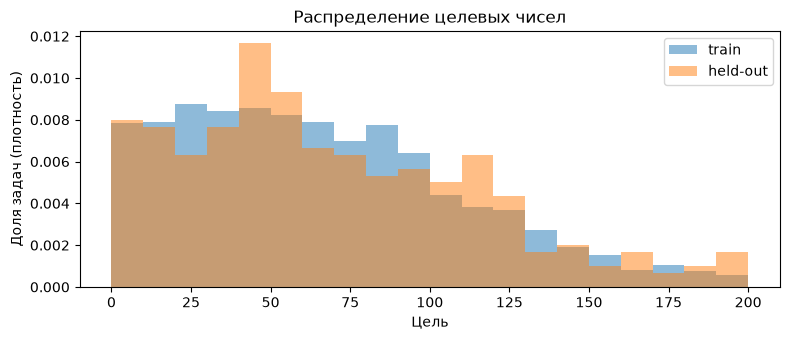

In [4]:
# Блок: примеры задач и распределение целей по сплитам
print("Примеры задач held-out:")
for task in heldout_tasks[:5]:
    print("  числа", task["numbers"], "-> цель", task["target"], "| эталон:", task["solution"])

figure, axis = plt.subplots(figsize=(8, 3.5))
bins = np.arange(0, 205, 10)
axis.hist([task["target"] for task in train_tasks], bins=bins, density=True, alpha=0.5, label="train")
axis.hist([task["target"] for task in heldout_tasks], bins=bins, density=True, alpha=0.5, label="held-out")
axis.set_title("Распределение целевых чисел")
axis.set_xlabel("Цель")
axis.set_ylabel("Доля задач (плотность)")
axis.legend()
plt.tight_layout()
plt.show()

### Подбор сложности

По заданию базовая модель должна решать примерно 10-50% задач. Для каждого варианта сложности задачи
генерировались той же процедурой с тем же seed, а базовая модель оценивалась только на val (`src/calibrate_difficulty.py`).

In [5]:
# Блок: результаты калибровки сложности (точность базовой модели на val)
with open(os.path.join(config.RESULTS_DIR, "calibration", "calibration_summary.json"), encoding="utf-8") as file:
    calibration = json.load(file)

calibration_rows = []
for row in calibration:
    calibration_rows.append({
        "Вариант": row["name"],
        "Чисел": row["num_count"],
        "Точность базы на val": round(row["val_accuracy"], 3),
        "Средняя длина ответа": round(row["mean_completion_tokens"], 1),
        "wrong_numbers": row["status_counts"]["wrong_numbers"],
        "wrong_value": row["status_counts"]["wrong_value"],
    })
pd.DataFrame(calibration_rows)

,Вариант,Чисел,Точность базы на val,Средняя длина ответа,wrong_numbers,wrong_value
0,n3_num1-50_t1-100,3,0.170,15.1,76,90
1,n3_num1-99_t1-199,3,0.275,16.1,35,110
2,n4_num1-50_t1-100,4,0.000,16.1,188,12
3,n4_num1-99_t1-199,4,0.015,17.0,176,21


С 4 числами базовая модель почти всегда теряет или подменяет число (точность 0-1.5%), это вне нужного диапазона.
Выбран вариант **3 числа из 1-99, цель 1-199**: 27.5% на val ближе всего к середине диапазона 10-50% и оставляет
место для роста.

## 4. Функция награды и её проверка

Награда (`src/reward.py`) проверяет ответ строго по заданию:

1. Берётся содержимое **последней** пары тегов `<answer></answer>`.
2. Внутри допускаются только цифры, пробелы, скобки и `+ - * /`. Типографские знаки умножения, деления и минуса
   (как в тексте условия) заменяются на `* / -`, так как это те же четыре операции.
3. Выражение разбирается `ast.parse(..., mode="eval")`. Разрешены только узлы `BinOp` с четырьмя операциями и целые
   константы. Унарный минус, степень, целочисленное деление, имена, вызовы функций запрещены.
4. Мультимножество чисел в выражении должно совпасть с исходным.
5. Значение считается вручную в `fractions.Fraction`. Деление на ноль - неверный ответ.
6. Награда 1, если значение точно равно цели, иначе 0.

Кроме награды функция возвращает статус проверки. Он не влияет на обучение, но нужен для анализа ошибок.

In [6]:
# Блок: исходный код проверки ответа (для удобства проверяющего)
print(inspect.getsource(check_answer))

def check_answer(completion, numbers, target):
    """
    Полная проверка одного ответа модели.

    Возвращает словарь:
        status     - один из статусов STATUS_*
        reward     - 1.0 если ответ верный, иначе 0.0
        expression - выражение из последнего тега (или None)
        value      - вычисленное значение в виде строки (или None)
    """
    result = {
        "status": STATUS_NO_ANSWER,
        "reward": 0.0,
        "expression": None,
        "value": None,
    }

    # Шаг 1. Достаём выражение из последней пары тегов
    expression = extract_answer(completion)
    if expression is None:
        return result
    expression = normalize_operators(expression)
    result["expression"] = expression

    # Шаг 2. Разрешены только цифры, пробелы, скобки и + - * /
    if not ALLOWED_CHARS_PATTERN.match(expression):
        result["status"] = STATUS_FORBIDDEN
        return result

    # Шаг 3. Разбор выражения модулем ast (без выполнения кода)
    try:
        tree = ast

In [7]:
# Блок: проверка награды на ловушках из задания и на попытках обхода
numbers = [3, 7, 25]
target = 46
trap_cases = [
    ("верный ответ", "Let me think. <answer>25 + 3 * 7</answer>", numbers, target, 1.0),
    ("типографский знак умножения", "<answer>25 + 3 \u00d7 7</answer>", numbers, target, 1.0),
    ("дописано = 46", "<answer>25 + 3 * 7 = 46</answer>", numbers, target, 0.0),
    ("в теге только цель", "<answer>46</answer>", numbers, target, 0.0),
    ("нет тегов", "25 + 3 * 7", numbers, target, 0.0),
    ("незакрытый тег", "<answer>25 + 3 * 7", numbers, target, 0.0),
    ("два тега, последний неверный", "<answer>25 + 3 * 7</answer> <answer>25 + 7 * 3 + 1</answer>", numbers, target, 0.0),
    ("два тега, последний верный", "<answer>25 * 3</answer> <answer>(7 * 3) + 25</answer>", numbers, target, 1.0),
    ("повтор числа", "<answer>25 + 7 + 7 + 7</answer>", numbers, target, 0.0),
    ("пропуск числа", "<answer>25 + 21</answer>", numbers, target, 0.0),
    ("склейка цифр 3 и 7", "<answer>37 + 25 - 16</answer>", numbers, target, 0.0),
    ("степень **", "<answer>3 ** 7 + 25</answer>", numbers, target, 0.0),
    ("целочисленное деление //", "<answer>25 // 3 + 7</answer>", numbers, target, 0.0),
    ("унарный минус", "<answer>-3 + 7 * 25</answer>", numbers, target, 0.0),
    ("дробная константа", "<answer>25.0 + 3 * 7</answer>", numbers, target, 0.0),
    ("попытка выполнить код", "<answer>__import__('os').system('ls')</answer>", numbers, target, 0.0),
    ("деление на ноль", "<answer>3 / (7 - 7) + 25</answer>", [3, 7, 7, 25], 46, 0.0),
    ("точная арифметика 1 / 3 * 3", "<answer>1 / 3 * 3</answer>", [1, 3, 3], 1, 1.0),
    ("дробный промежуточный результат", "<answer>(1 + 7 / 3) * 3</answer>", [1, 7, 3, 3], 10, 1.0),
    ("верные числа, неверное значение", "<answer>25 * 3 + 7</answer>", numbers, target, 0.0),
]

trap_rows = []
all_passed = True
for name, text, case_numbers, case_target, expected_reward in trap_cases:
    result = check_answer(text, case_numbers, case_target)
    passed = result["reward"] == expected_reward
    if not passed:
        all_passed = False
    trap_rows.append({"Случай": name, "Ответ модели": text, "Статус": result["status"],
                      "Награда": result["reward"], "Ожидалось": expected_reward, "OK": passed})

print("Все случаи совпали с ожиданием:", all_passed)
pd.DataFrame(trap_rows)

Все случаи совпали с ожиданием: True


,Случай,Ответ модели,Статус,Награда,Ожидалось,OK
0,верный ответ,Let me think. <answer>25 + 3 * 7</answer>,correct,1.0,1.0,True
1,типографский знак умножения,<answer>25 + 3 × 7</answer>,correct,1.0,1.0,True
2,дописано = 46,<answer>25 + 3 * 7 = 46</answer>,forbidden_syntax,0.0,0.0,True
3,в теге только цель,<answer>46</answer>,wrong_numbers,0.0,0.0,True
4,нет тегов,25 + 3 * 7,no_answer,0.0,0.0,True
5,незакрытый тег,<answer>25 + 3 * 7,no_answer,0.0,0.0,True
6,"два тега, последний неверный",<answer>25 + 3 * 7</answer> <answer>25 + 7 * 3 + 1</answer>,wrong_numbers,0.0,0.0,True
7,"два тега, последний верный",<answer>25 * 3</answer> <answer>(7 * 3) + 25</answer>,correct,1.0,1.0,True
8,повтор числа,<answer>25 + 7 + 7 + 7</answer>,wrong_numbers,0.0,0.0,True
9,пропуск числа,<answer>25 + 21</answer>,wrong_numbers,0.0,0.0,True


## 5. Базовая модель: промпт и точность до обучения

Промпт содержит правила из задания и пример из условия. Модель запускается в режиме без рассуждений
(`enable_thinking=False`), поэтому шаблон чата Qwen3 добавляет пустой блок `<think></think>`.
Оценка всех моделей одинаковая: жадное декодирование (`do_sample=False`), не более 256 новых токенов,
батч 32, одна и та же строгая проверка.

In [8]:
# Блок: как выглядит промпт для модели (нужен только токенизатор, GPU не используется)
from src.model_utils import build_prompt, load_tokenizer

tokenizer = load_tokenizer()
example_task = heldout_tasks[0]
example_prompt = build_prompt(tokenizer, example_task["numbers"], example_task["target"])
print(example_prompt)
print("Длина промпта, токенов:", len(tokenizer(example_prompt, add_special_tokens=False)["input_ids"]))

<|im_start|>user
Using the numbers 25, 92, 73, create an arithmetic expression that equals 44.
Rules:
- Use each number exactly once.
- You may use only +, -, *, / and parentheses.
- Do not use any other numbers or operations, and do not concatenate digits.
Think briefly, then write the final expression inside <answer></answer> tags without "= 44" at the end.
Example: numbers 3, 7, 25 and target 46 -> <answer>25 + 3 * 7</answer><|im_end|>
<|im_start|>assistant
<think>

</think>


Длина промпта, токенов: 132


In [9]:
# Блок: точность базовой модели на held-out (результат python -m src.evaluate --split heldout --name base)
base_summary = analysis.load_base_summary("heldout")
print("Точность базовой модели на held-out:", round(base_summary["accuracy"], 4),
      "(", base_summary["num_correct"], "из", base_summary["num_tasks"], ")")
print("Средняя длина ответа, токенов:", round(base_summary["mean_completion_tokens"], 1))
print("Статусы проверки:", base_summary["status_counts"])

base_answers = analysis.load_answers(None, 0, "heldout")
example_rows = []
for record in base_answers[:8]:
    example_rows.append({"Числа": record["numbers"], "Цель": record["target"],
                         "Ответ базы": record["completion"], "Статус": record["status"]})
pd.DataFrame(example_rows)

Точность базовой модели на held-out: 0.2033 ( 61 из 300 )
Средняя длина ответа, токенов: 16.0
Статусы проверки: {'correct': 61, 'no_answer': 0, 'forbidden_syntax': 0, 'parse_error': 0, 'wrong_numbers': 65, 'division_by_zero': 0, 'wrong_value': 174}


,Числа,Цель,Ответ базы,Статус
0,"[25, 92, 73]",44,<answer>92 + 73 - 25</answer>,wrong_value
1,"[30, 78, 7]",101,<answer>78 + 3 * 7</answer>,wrong_numbers
2,"[13, 51, 44]",91,<answer>51 + 44 - 13</answer>,wrong_value
3,"[44, 29, 46]",27,<answer>46 + 29 - 44</answer>,wrong_value
4,"[98, 3, 95]",6,<answer>95 + 3</answer>,wrong_numbers
5,"[1, 89, 96]",184,<answer>96 + 89</answer>,wrong_numbers
6,"[74, 12, 15]",71,<answer>15 + 74 - 12</answer>,wrong_value
7,"[61, 76, 55]",40,<answer>55 + 61 - 76</answer>,correct


База решает около 20% задач held-out, это внутри требуемого диапазона 10-50%. Формат ответа модель соблюдает
всегда (ни одного `no_answer`), но рассуждения не пишет и сразу выдаёт выражение длиной около 16 токенов.
Ошибки двух типов: верные числа, но неверное значение (`wrong_value`), и потерянное или лишнее число (`wrong_numbers`).
Встречается и копирование примера из промпта: на задаче (30, 78, 7) -> 101 модель ответила `78 + 3 * 7`.

## 6. Обучение GRPO

Алгоритм (`src/train_grpo.py`, `trl.GRPOTrainer`):

1. На каждом шаге берётся 8 задач из train, для каждой модель сэмплирует группу из G = 8 ответов (температура 1.0).
2. Каждый ответ получает награду своего условия: строгую бинарную в `baseline`, частичную за близость в `partial` (раздел 1.2).
3. Преимущество ответа = (награда - среднее по группе) / std по группе. Если все 8 ответов в группе получили
   одинаковую награду, преимущество нулевое и группа не даёт сигнала (эта доля логируется как `frac_reward_zero_std`).
4. Политика обновляется по клиппированной функции потерь GRPO с KL-штрафом к исходной модели (beta = 0.04, как в
   статье GRPO). Референсом служит та же модель с отключённым LoRA-адаптером.
5. Обучается только LoRA-адаптер (около 10 млн параметров, 1.7% модели), база заморожена.

Каждые 10 шагов сохраняется чекпойнт, каждые 25 шагов модель оценивается жадным декодированием на held-out.
Held-out не используется для выбора чекпойнта: итоговая модель - последний шаг.

### Пилотный запуск (выбор learning rate и числа шагов)

Перед полными запусками был сделан пилот на 50 шагов с lr = 2e-5. Чтобы held-out не участвовал ни в каком выборе,
по ходу пилота модель оценивалась на val. В пилоте также проверено продолжение обучения после остановки:
процесс был остановлен после чекпойнта шага 20 и продолжил работу с шага 21.

In [10]:
# Блок: результаты пилота на val
pilot_curve = analysis.load_eval_curve("pilot_lr2e-5", split="val")
print(pilot_curve[["step", "accuracy", "mean_completion_tokens", "count_wrong_numbers", "count_wrong_value"]])

pilot_log = analysis.load_train_log("pilot_lr2e-5")
pilot_windows = []
for start in range(1, 51, 10):
    window = pilot_log[(pilot_log["step"] >= start) & (pilot_log["step"] < start + 10)]
    pilot_windows.append({
        "Шаги": str(start) + "-" + str(start + 9),
        "reward": round(window["reward"].mean(), 3),
        "доля wrong_numbers": round(window["status/wrong_numbers"].mean(), 3),
        "KL": round(window["kl"].mean(), 4),
        "длина ответа": round(window["completions/mean_length"].mean(), 1),
        "frac_reward_zero_std": round(window["frac_reward_zero_std"].mean(), 2),
        "энтропия": round(window["entropy"].mean(), 3),
    })
pd.DataFrame(pilot_windows)

   step  accuracy  mean_completion_tokens  count_wrong_numbers  count_wrong_value
0     0     0.275                  16.145                   35                110
1    25     0.375                  16.660                    2                123
2    50     0.550                  16.680                    1                 89


,Шаги,reward,доля wrong_numbers,KL,длина ответа,frac_reward_zero_std,энтропия
0,1-10,0.222,0.189,0.0021,16.2,0.31,0.153
1,11-20,0.261,0.056,0.0309,16.7,0.34,0.126
2,21-30,0.281,0.027,0.0630,16.7,0.45,0.109
3,31-40,0.359,0.022,0.1396,16.7,0.36,0.095
4,41-50,0.425,0.039,0.1276,16.7,0.42,0.075


За 50 шагов точность на val выросла с 27.5% до 55%, поэтому lr = 2e-5 оставлен. Для полных запусков выбрано
150 шагов: это около 80 минут на запуск на GTX 1060 и укладывается в бюджет 3 seed на каждое условие.

## 7. Динамика обучения

На всех графиках по шагам: линия - среднее по seed, полоса - минимум и максимум по seed.
Метрики, которые считаются на обучающих ответах (награда, KL, длина), сглажены скользящим средним по 10 шагам,
потому что на одном шаге всего 8 задач. Точность на held-out не сглаживается: это отдельные оценки на 300 задачах
каждые 25 шагов. Шаг 0 - базовая модель (в начале обучения LoRA-адаптер нулевой).

In [11]:
# Блок: список запусков. В отчёт попадают только завершённые запуски (есть DONE.json)
INCLUDE_UNFINISHED = False
CONDITIONS = ["baseline", "partial"]
CONDITION_LABELS = {"baseline": "baseline: строгая награда 0/1", "partial": "partial: частичная награда за близость"}
CONDITION_COLORS = {"baseline": "tab:blue", "partial": "tab:orange"}
SMOOTH_WINDOW = 10

runs = {}
for condition in CONDITIONS:
    runs[condition] = []
    for seed in config.TRAIN_SEEDS:
        run_name = condition + "_seed" + str(seed)
        run_dir = os.path.join(config.RESULTS_DIR, run_name)
        if analysis.run_is_done(run_name) or (INCLUDE_UNFINISHED and os.path.isdir(run_dir)):
            runs[condition].append(run_name)
    print(condition, "- запусков в отчёте:", len(runs[condition]), runs[condition])

train_logs = {}
heldout_curves = {}
for condition in CONDITIONS:
    train_logs[condition] = []
    heldout_curves[condition] = []
    for run_name in runs[condition]:
        train_logs[condition].append(analysis.load_train_log(run_name))
        heldout_curves[condition].append(analysis.load_eval_curve(run_name, "heldout"))
        print(run_name, "| шагов в логе:", len(train_logs[condition][-1]),
              "| точек оценки held-out:", len(heldout_curves[condition][-1]))

baseline - запусков в отчёте: 3 ['baseline_seed0', 'baseline_seed1', 'baseline_seed2']
partial - запусков в отчёте: 3 ['partial_seed0', 'partial_seed1', 'partial_seed2']
baseline_seed0 | шагов в логе: 150 | точек оценки held-out: 7
baseline_seed1 | шагов в логе: 150 | точек оценки held-out: 7
baseline_seed2 | шагов в логе: 150 | точек оценки held-out: 7
partial_seed0 | шагов в логе: 150 | точек оценки held-out: 7
partial_seed1 | шагов в логе: 150 | точек оценки held-out: 7
partial_seed2 | шагов в логе: 150 | точек оценки held-out: 7


In [12]:
# Блок: функции для графиков (среднее по seed и полоса мин-макс)
def plot_train_metric(axis, condition, column, smooth=True):
    tables = train_logs[condition]
    if len(tables) == 0:
        return
    prepared = []
    for table in tables:
        if smooth:
            prepared.append(analysis.rolling_mean(table, column, SMOOTH_WINDOW))
        else:
            prepared.append(table[["step", column]])
    stats = analysis.mean_and_spread_by_step(prepared, column)
    label = CONDITION_LABELS[condition] + " (seed: " + str(len(tables)) + ")"
    axis.plot(stats["step"], stats["mean"], color=CONDITION_COLORS[condition], label=label)
    axis.fill_between(stats["step"], stats["min"], stats["max"], color=CONDITION_COLORS[condition], alpha=0.2)


def plot_heldout_metric(axis, condition, column):
    tables = heldout_curves[condition]
    if len(tables) == 0:
        return
    stats = analysis.mean_and_spread_by_step(tables, column)
    label = CONDITION_LABELS[condition] + " (seed: " + str(len(tables)) + ")"
    axis.plot(stats["step"], stats["mean"], marker="o", color=CONDITION_COLORS[condition], label=label)
    axis.fill_between(stats["step"], stats["min"], stats["max"], color=CONDITION_COLORS[condition], alpha=0.2)

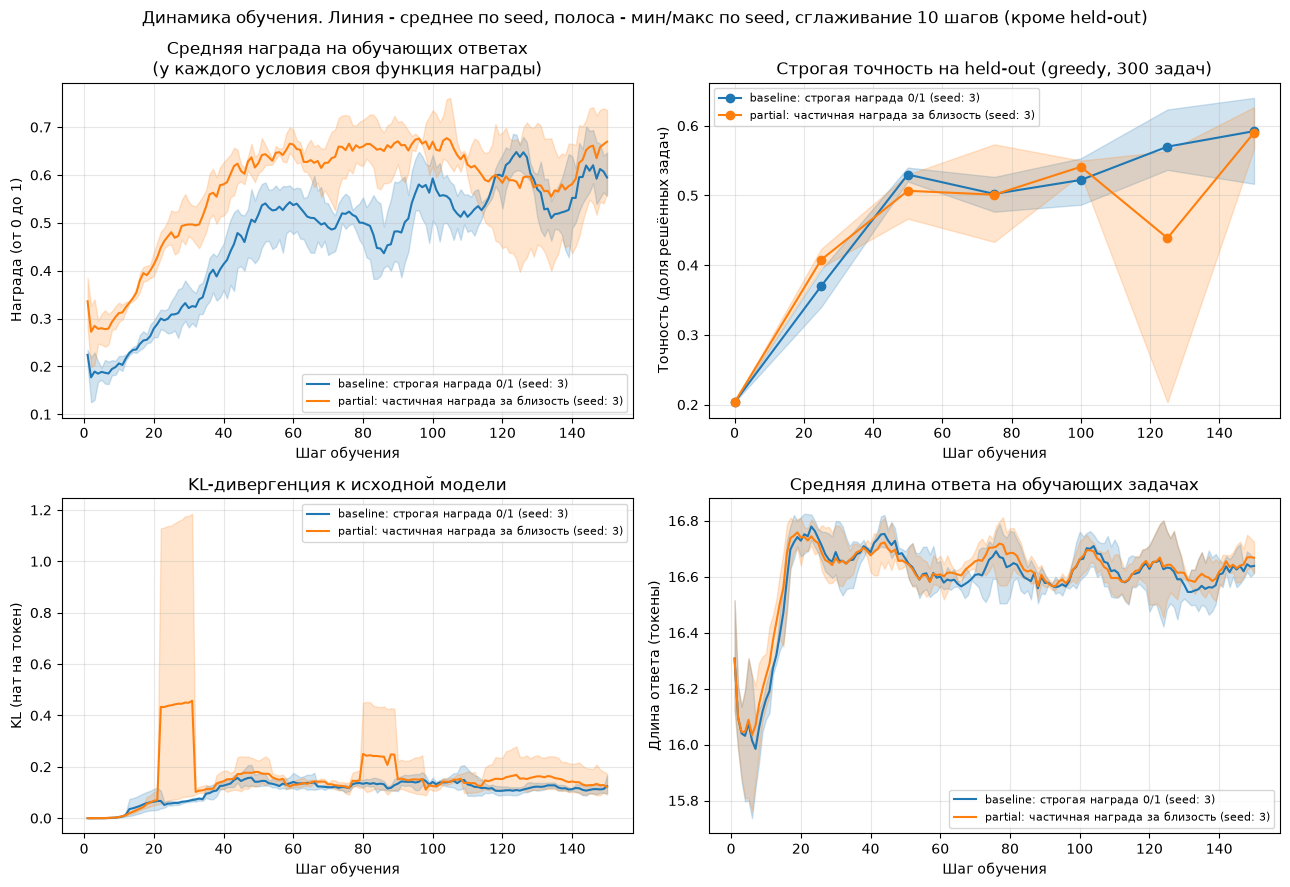

In [13]:
# Блок: обязательные графики по шагам - награда, точность на held-out, KL, длина ответа
figure, axes = plt.subplots(2, 2, figsize=(13, 9))

for condition in CONDITIONS:
    plot_train_metric(axes[0, 0], condition, "reward")
axes[0, 0].set_title("Средняя награда на обучающих ответах\n(у каждого условия своя функция награды)")
axes[0, 0].set_xlabel("Шаг обучения")
axes[0, 0].set_ylabel("Награда (от 0 до 1)")

for condition in CONDITIONS:
    plot_heldout_metric(axes[0, 1], condition, "accuracy")
axes[0, 1].set_title("Строгая точность на held-out (greedy, 300 задач)")
axes[0, 1].set_xlabel("Шаг обучения")
axes[0, 1].set_ylabel("Точность (доля решённых задач)")

for condition in CONDITIONS:
    plot_train_metric(axes[1, 0], condition, "kl")
axes[1, 0].set_title("KL-дивергенция к исходной модели")
axes[1, 0].set_xlabel("Шаг обучения")
axes[1, 0].set_ylabel("KL (нат на токен)")

for condition in CONDITIONS:
    plot_train_metric(axes[1, 1], condition, "completions/mean_length")
axes[1, 1].set_title("Средняя длина ответа на обучающих задачах")
axes[1, 1].set_xlabel("Шаг обучения")
axes[1, 1].set_ylabel("Длина ответа (токены)")

for axis in axes.flatten():
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
figure.suptitle("Динамика обучения. Линия - среднее по seed, полоса - мин/макс по seed, сглаживание 10 шагов (кроме held-out)")
plt.tight_layout()
plt.show()

baseline_seed0 | медиана KL по всем шагам: 0.099 | три самых больших значения: ['шаг 35: 0.61', 'шаг 89: 0.48', 'шаг 77: 0.4']
baseline_seed1 | медиана KL по всем шагам: 0.111 | три самых больших значения: ['шаг 57: 0.59', 'шаг 150: 0.51', 'шаг 13: 0.51']
baseline_seed2 | медиана KL по всем шагам: 0.09 | три самых больших значения: ['шаг 39: 0.46', 'шаг 100: 0.43', 'шаг 43: 0.42']
partial_seed0 | медиана KL по всем шагам: 0.129 | три самых больших значения: ['шаг 22: 10.81', 'шаг 80: 3.23', 'шаг 115: 0.59']
partial_seed1 | медиана KL по всем шагам: 0.109 | три самых больших значения: ['шаг 88: 1.29', 'шаг 77: 0.93', 'шаг 38: 0.7']
partial_seed2 | медиана KL по всем шагам: 0.091 | три самых больших значения: ['шаг 99: 0.59', 'шаг 128: 0.29', 'шаг 71: 0.26']


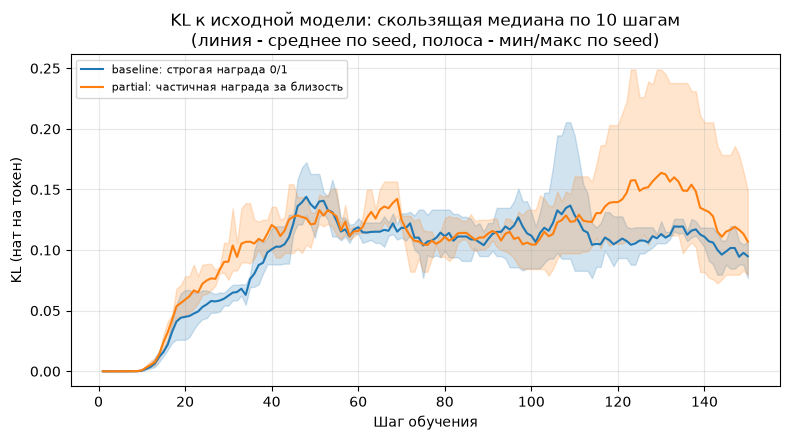

In [14]:
# Блок: KL без влияния одиночных выбросов - скользящая медиана вместо скользящего среднего
# На графике выше у partial есть "плато" KL около 0.45 на шагах 22-31. Это один шаг partial_seed0 с KL около 10.8,
# растянутый скользящим средним на 10 шагов. Медиана по окну к таким одиночным выбросам устойчива.
for condition in CONDITIONS:
    for run_index, run_name in enumerate(runs[condition]):
        table = train_logs[condition][run_index]
        top = table.nlargest(3, "kl")
        top_text = []
        for _, row in top.iterrows():
            top_text.append("шаг " + str(int(row["step"])) + ": " + str(round(row["kl"], 2)))
        print(run_name, "| медиана KL по всем шагам:", round(table["kl"].median(), 3),
              "| три самых больших значения:", top_text)

figure, axis = plt.subplots(figsize=(8, 4.5))
for condition in CONDITIONS:
    prepared = []
    for table in train_logs[condition]:
        smoothed = table[["step"]].copy()
        smoothed["kl"] = table["kl"].rolling(window=SMOOTH_WINDOW, min_periods=1).median()
        prepared.append(smoothed)
    stats = analysis.mean_and_spread_by_step(prepared, "kl")
    axis.plot(stats["step"], stats["mean"], color=CONDITION_COLORS[condition], label=CONDITION_LABELS[condition])
    axis.fill_between(stats["step"], stats["min"], stats["max"], color=CONDITION_COLORS[condition], alpha=0.2)
axis.set_title("KL к исходной модели: скользящая медиана по 10 шагам\n(линия - среднее по seed, полоса - мин/макс по seed)")
axis.set_xlabel("Шаг обучения")
axis.set_ylabel("KL (нат на токен)")
axis.grid(alpha=0.3)
axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

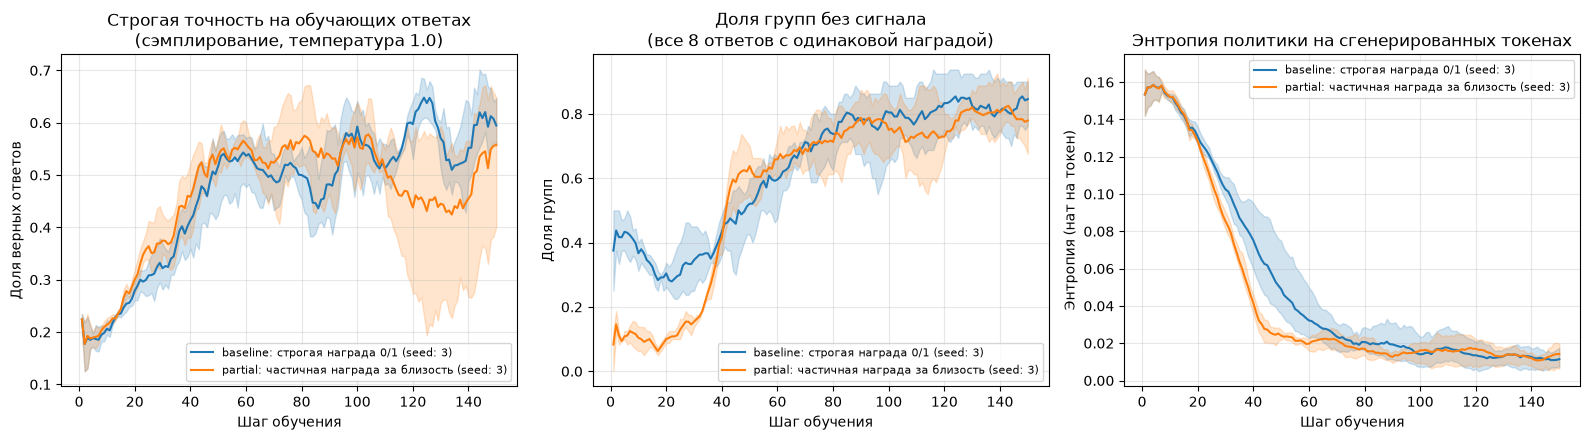

In [15]:
# Блок: механизм - строгая точность на обучающих ответах, доля групп без сигнала и энтропия
figure, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for condition in CONDITIONS:
    plot_train_metric(axes[0], condition, "status/correct")
axes[0].set_title("Строгая точность на обучающих ответах\n(сэмплирование, температура 1.0)")
axes[0].set_xlabel("Шаг обучения")
axes[0].set_ylabel("Доля верных ответов")

for condition in CONDITIONS:
    plot_train_metric(axes[1], condition, "frac_reward_zero_std")
axes[1].set_title("Доля групп без сигнала\n(все 8 ответов с одинаковой наградой)")
axes[1].set_xlabel("Шаг обучения")
axes[1].set_ylabel("Доля групп")

for condition in CONDITIONS:
    plot_train_metric(axes[2], condition, "entropy")
axes[2].set_title("Энтропия политики на сгенерированных токенах")
axes[2].set_xlabel("Шаг обучения")
axes[2].set_ylabel("Энтропия (нат на токен)")

for axis in axes:
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

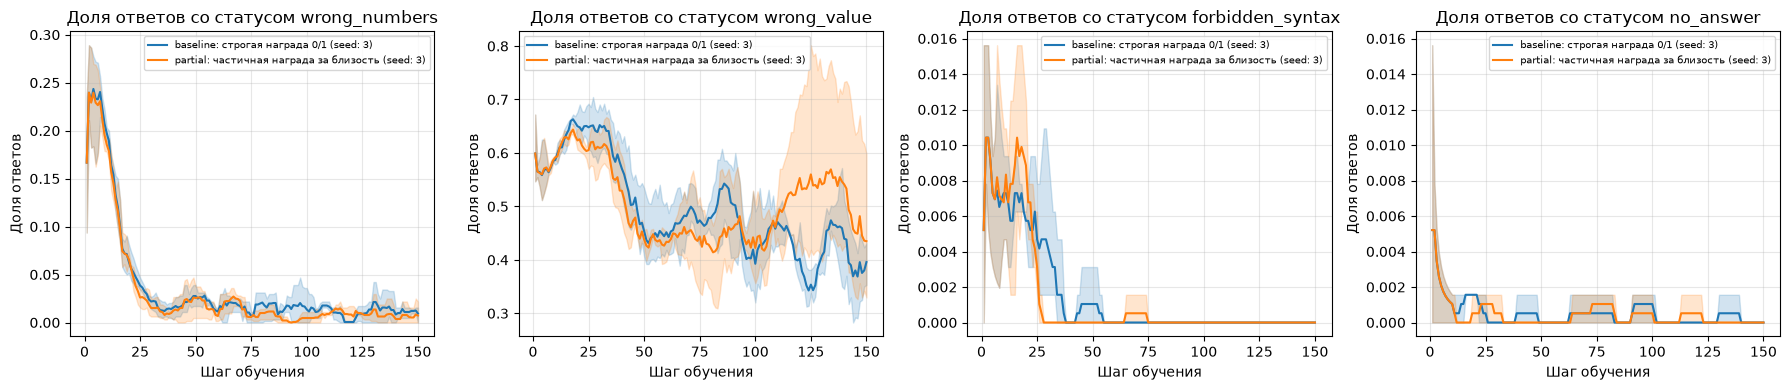

In [16]:
# Блок: типы ошибок на обучающих ответах по шагам
error_statuses = ["wrong_numbers", "wrong_value", "forbidden_syntax", "no_answer"]
figure, axes = plt.subplots(1, len(error_statuses), figsize=(18, 4))
for index, status in enumerate(error_statuses):
    for condition in CONDITIONS:
        plot_train_metric(axes[index], condition, "status/" + status)
    axes[index].set_title("Доля ответов со статусом " + status)
    axes[index].set_xlabel("Шаг обучения")
    axes[index].set_ylabel("Доля ответов")
    axes[index].grid(alpha=0.3)
    axes[index].legend(fontsize=7)
plt.tight_layout()
plt.show()

## 8. Итоговое сравнение на held-out

Все модели оценены одинаково: жадное декодирование, одна и та же отложенная выборка из 300 задач, строгая проверка.
Итоговая модель каждого запуска - последний шаг обучения (held-out не использовался для выбора чекпойнта).

In [17]:
# Блок: итоговая точность каждого запуска и признаки reward hacking
base_answers = analysis.load_answers(None, 0, "heldout")
base_indicators = analysis.hacking_indicators(base_answers)
final_rows = [{
    "Модель": "база (до обучения)", "Условие": "-", "Seed": "-",
    "Точность": base_summary["accuracy"], "Решено из 300": base_summary["num_correct"],
    "wrong_numbers": base_summary["status_counts"]["wrong_numbers"],
    "wrong_value": base_summary["status_counts"]["wrong_value"],
    "Длина ответа": base_summary["mean_completion_tokens"],
    "KL (посл. 10 шагов)": 0.0,
    "Почти попадания": base_indicators["near_miss_share"],
    "Ответ = сумма чисел": base_indicators["sum_of_numbers_share"],
    "Медиана отн. ошибки": base_indicators["median_relative_error_wrong_value"],
}]

final_answers = {}
for condition in CONDITIONS:
    for run_index, run_name in enumerate(runs[condition]):
        curve = heldout_curves[condition][run_index]
        last = curve[curve["step"] == curve["step"].max()].iloc[0]
        train_log = train_logs[condition][run_index]
        answers = analysis.load_answers(run_name, int(last["step"]), "heldout")
        final_answers[run_name] = answers
        indicators = analysis.hacking_indicators(answers)
        final_rows.append({
            "Модель": run_name, "Условие": condition, "Seed": run_name.split("seed")[-1],
            "Точность": last["accuracy"], "Решено из 300": int(last["num_correct"]),
            "wrong_numbers": int(last["count_wrong_numbers"]), "wrong_value": int(last["count_wrong_value"]),
            "Длина ответа": last["mean_completion_tokens"],
            "KL (посл. 10 шагов)": train_log["kl"].tail(10).mean(),
            "Почти попадания": indicators["near_miss_share"],
            "Ответ = сумма чисел": indicators["sum_of_numbers_share"],
            "Медиана отн. ошибки": indicators["median_relative_error_wrong_value"],
        })
        print(run_name, "| итоговый шаг:", int(last["step"]), "| точность:", round(last["accuracy"], 4))

final_table = pd.DataFrame(final_rows)
final_table.round(4)

baseline_seed0 | итоговый шаг: 150 | точность: 0.64
baseline_seed1 | итоговый шаг: 150 | точность: 0.62
baseline_seed2 | итоговый шаг: 150 | точность: 0.5167
partial_seed0 | итоговый шаг: 150 | точность: 0.5667
partial_seed1 | итоговый шаг: 150 | точность: 0.6267
partial_seed2 | итоговый шаг: 150 | точность: 0.5767


,Модель,Условие,Seed,Точность,Решено из 300,wrong_numbers,wrong_value,Длина ответа,KL (посл. 10 шагов),Почти попадания,Ответ = сумма чисел,Медиана отн. ошибки
0,база (до обучения),-,-,0.2033,61,65,174,16.0200,0.0000,0.0467,0.0067,0.7078
1,baseline_seed0,baseline,0,0.6400,192,1,107,16.6300,0.1099,0.0600,0.0000,0.4082
2,baseline_seed1,baseline,1,0.6200,186,5,109,16.6300,0.1665,0.0567,0.0033,0.4516
3,baseline_seed2,baseline,2,0.5167,155,4,141,16.5867,0.0967,0.0600,0.0000,0.4844
4,partial_seed0,partial,0,0.5667,170,1,129,16.6167,0.1737,0.0733,0.1000,0.3704
5,partial_seed1,partial,1,0.6267,188,1,111,16.6267,0.0981,0.0633,0.0000,0.4107
6,partial_seed2,partial,2,0.5767,173,3,124,16.5967,0.0918,0.0500,0.0200,0.6026


In [18]:
# Блок: сводка по условиям (среднее, std, мин, макс по seed) и попарное сравнение seed
summary_rows = [{"Условие": "база (до обучения)", "Seed": 1, "Точность, среднее": base_summary["accuracy"],
                 "std": 0.0, "мин": base_summary["accuracy"], "макс": base_summary["accuracy"]}]
for condition in CONDITIONS:
    part = final_table[final_table["Условие"] == condition]
    if len(part) == 0:
        continue
    summary_rows.append({
        "Условие": condition, "Seed": len(part),
        "Точность, среднее": part["Точность"].mean(), "std": part["Точность"].std(ddof=0),
        "мин": part["Точность"].min(), "макс": part["Точность"].max(),
    })
print("Строгая точность на held-out (300 задач):")
print(pd.DataFrame(summary_rows).round(4).to_string(index=False))

print()
print("Попарное сравнение (partial минус baseline при одинаковом seed):")
for seed in config.TRAIN_SEEDS:
    baseline_name = "baseline_seed" + str(seed)
    partial_name = "partial_seed" + str(seed)
    baseline_row = final_table[final_table["Модель"] == baseline_name]
    partial_row = final_table[final_table["Модель"] == partial_name]
    if len(baseline_row) == 1 and len(partial_row) == 1:
        difference = partial_row["Точность"].iloc[0] - baseline_row["Точность"].iloc[0]
        print("  seed", seed, ": разница точности =", round(difference, 4))
    else:
        print("  seed", seed, ": нет пары запусков")

# стандартная ошибка доли на 300 задачах - ориентир для масштаба шума одной оценки
p = base_summary["accuracy"]
print()
print("Стандартная ошибка доли для одной оценки на 300 задачах при p =", round(p, 2), ":", round((p * (1 - p) / 300) ** 0.5, 4))

Строгая точность на held-out (300 задач):
           Условие  Seed  Точность, среднее    std    мин   макс
база (до обучения)     1             0.2033 0.0000 0.2033 0.2033
          baseline     3             0.5922 0.0540 0.5167 0.6400
           partial     3             0.5900 0.0262 0.5667 0.6267

Попарное сравнение (partial минус baseline при одинаковом seed):
  seed 0 : разница точности = -0.0733
  seed 1 : разница точности = 0.0067
  seed 2 : разница точности = 0.06

Стандартная ошибка доли для одной оценки на 300 задачах при p = 0.2 : 0.0232


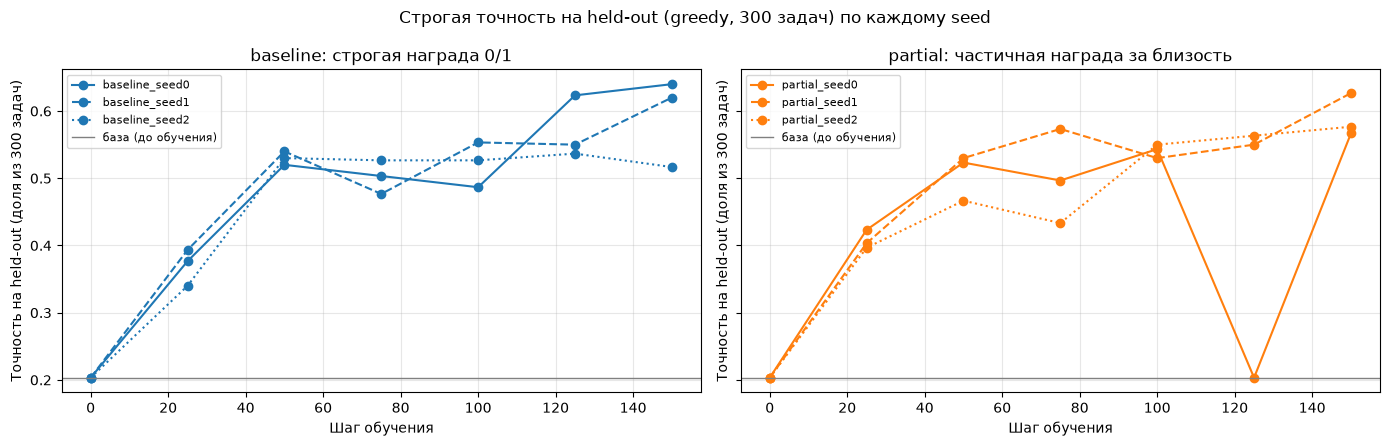

Точность на held-out по шагам, %:
        Запуск  шаг 0  шаг 25  шаг 50  шаг 75  шаг 100  шаг 125  шаг 150
baseline_seed0   20.3    37.7    52.0    50.3     48.7     62.3     64.0
baseline_seed1   20.3    39.3    54.0    47.7     55.3     55.0     62.0
baseline_seed2   20.3    34.0    53.0    52.7     52.7     53.7     51.7
 partial_seed0   20.3    42.3    52.3    49.7     54.3     20.3     56.7
 partial_seed1   20.3    40.3    53.0    57.3     53.0     55.0     62.7
 partial_seed2   20.3    39.7    46.7    43.3     55.0     56.3     57.7


In [19]:
# Блок: точность на held-out по шагам для каждого seed отдельно
# Среднее по seed может скрыть то, что происходит внутри отдельного запуска, поэтому показываем все 6 кривых.
SEED_LINE_STYLES = ["-", "--", ":"]

figure, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for index, condition in enumerate(CONDITIONS):
    axis = axes[index]
    for run_index, run_name in enumerate(runs[condition]):
        curve = heldout_curves[condition][run_index]
        axis.plot(curve["step"], curve["accuracy"], marker="o", linestyle=SEED_LINE_STYLES[run_index],
                  color=CONDITION_COLORS[condition], label=run_name)
    axis.axhline(base_summary["accuracy"], color="gray", linewidth=1, label="база (до обучения)")
    axis.set_title(CONDITION_LABELS[condition])
    axis.set_xlabel("Шаг обучения")
    axis.set_ylabel("Точность на held-out (доля из 300 задач)")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
figure.suptitle("Строгая точность на held-out (greedy, 300 задач) по каждому seed")
plt.tight_layout()
plt.show()

rows = []
for condition in CONDITIONS:
    for run_index, run_name in enumerate(runs[condition]):
        curve = heldout_curves[condition][run_index]
        row = {"Запуск": run_name}
        for _, point in curve.iterrows():
            row["шаг " + str(int(point["step"]))] = round(100 * point["accuracy"], 1)
        rows.append(row)
print("Точность на held-out по шагам, %:")
print(pd.DataFrame(rows).to_string(index=False))

In [20]:
# Блок: проверка оценки - итоговые адаптеры переоценены отдельно от обучения
# Команда: python -m src.evaluate --split heldout --name recheck_<запуск>_final --adapter checkpoints/<запуск>/final_adapter
# Оценка по ходу обучения делается внутри тренера (callback). Здесь проверяем, что сохранённый адаптер,
# загруженный заново, даёт на held-out те же ответы.
for run_name in ["baseline_seed0", "partial_seed0"]:
    recheck_path = os.path.join(config.RESULTS_DIR, "eval", "heldout_recheck_" + run_name + "_final_answers.jsonl")
    if not os.path.exists(recheck_path):
        print(run_name, "- переоценки нет")
        continue
    recheck_answers = analysis.read_jsonl(recheck_path)
    inside_answers = final_answers[run_name]
    same_text = 0
    recheck_correct = 0
    inside_correct = 0
    for recheck_record, inside_record in zip(recheck_answers, inside_answers):
        if recheck_record["completion"] == inside_record["completion"]:
            same_text += 1
        if recheck_record["status"] == "correct":
            recheck_correct += 1
        if inside_record["status"] == "correct":
            inside_correct += 1
    print(run_name, "| отдельная оценка:", recheck_correct, "из", len(recheck_answers),
          "| оценка внутри обучения (шаг 150):", inside_correct, "из", len(inside_answers),
          "| ответов совпало дословно:", same_text)

baseline_seed0 | отдельная оценка: 192 из 300 | оценка внутри обучения (шаг 150): 192 из 300 | ответов совпало дословно: 300
partial_seed0 | отдельная оценка: 170 из 300 | оценка внутри обучения (шаг 150): 170 из 300 | ответов совпало дословно: 300


## 9. Ответы модели до и после обучения

Таблица показывает ответы базовой модели и итоговых моделей обоих условий (seed 0) на одних и тех же задачах held-out.
Задачи взяты подряд с начала held-out, без отбора. Ниже - сводка переходов по всем 300 задачам.

In [21]:
# Блок: таблица ответов до и после обучения на одних и тех же задачах
compare_runs = []
for condition in CONDITIONS:
    if len(runs[condition]) > 0:
        compare_runs.append(runs[condition][0])

rows = []
for index in range(15):
    base_record = base_answers[index]
    row = {"Числа": base_record["numbers"], "Цель": base_record["target"],
           "База": base_record["completion"].strip(), "База: статус": base_record["status"]}
    for run_name in compare_runs:
        record = final_answers[run_name][index]
        row[run_name] = record["completion"].strip()
        row[run_name + ": статус"] = record["status"]
    rows.append(row)
pd.DataFrame(rows)

,Числа,Цель,База,База: статус,baseline_seed0,baseline_seed0: статус,partial_seed0,partial_seed0: статус
0,"[25, 92, 73]",44,<answer>92 + 73 - 25</answer>,wrong_value,<answer>92 - 73 + 25</answer>,correct,<answer>92 - 73 + 25</answer>,correct
1,"[30, 78, 7]",101,<answer>78 + 3 * 7</answer>,wrong_numbers,<answer>78 + 30 - 7</answer>,correct,<answer>78 + 30 - 7</answer>,correct
2,"[13, 51, 44]",91,<answer>51 + 44 - 13</answer>,wrong_value,<answer>51 + 44 - 13</answer>,wrong_value,<answer>51 + 44 - 13</answer>,wrong_value
3,"[44, 29, 46]",27,<answer>46 + 29 - 44</answer>,wrong_value,<answer>46 - 44 + 29</answer>,wrong_value,<answer>44 - 46 + 29</answer>,correct
4,"[98, 3, 95]",6,<answer>95 + 3</answer>,wrong_numbers,<answer>98 - 95 + 3</answer>,correct,<answer>98 - 95 + 3</answer>,correct
5,"[1, 89, 96]",184,<answer>96 + 89</answer>,wrong_numbers,<answer>96 + 89 - 1</answer>,correct,<answer>96 + 89 - 1</answer>,correct
6,"[74, 12, 15]",71,<answer>15 + 74 - 12</answer>,wrong_value,<answer>74 - 15 + 12</answer>,correct,<answer>74 - 15 + 12</answer>,correct
7,"[61, 76, 55]",40,<answer>55 + 61 - 76</answer>,correct,<answer>55 - 76 + 61</answer>,correct,<answer>61 - 76 + 55</answer>,correct
8,"[4, 40, 37]",7,<answer>40 + 37 - 4</answer>,wrong_value,<answer>40 - 37 + 4</answer>,correct,<answer>40 - 37 + 4</answer>,correct
9,"[67, 74, 30]",37,<answer>74 - 30 - 67</answer>,wrong_value,<answer>74 - 67 + 30</answer>,correct,<answer>67 - 74 + 30</answer>,wrong_value


In [22]:
# Блок: переходы между "решено" и "не решено" для всех 300 задач held-out (база -> итоговая модель)
for run_name in final_answers:
    answers = final_answers[run_name]
    stayed_correct = 0
    fixed = 0
    broken = 0
    stayed_wrong = 0
    for base_record, record in zip(base_answers, answers):
        base_ok = base_record["status"] == "correct"
        now_ok = record["status"] == "correct"
        if base_ok and now_ok:
            stayed_correct += 1
        elif not base_ok and now_ok:
            fixed += 1
        elif base_ok and not now_ok:
            broken += 1
        else:
            stayed_wrong += 1
    print(run_name, "| было верно и осталось:", stayed_correct, "| исправлено:", fixed,
          "| сломано:", broken, "| осталось неверно:", stayed_wrong)

baseline_seed0 | было верно и осталось: 45 | исправлено: 147 | сломано: 16 | осталось неверно: 92
baseline_seed1 | было верно и осталось: 52 | исправлено: 134 | сломано: 9 | осталось неверно: 105
baseline_seed2 | было верно и осталось: 34 | исправлено: 121 | сломано: 27 | осталось неверно: 118
partial_seed0 | было верно и осталось: 40 | исправлено: 130 | сломано: 21 | осталось неверно: 109
partial_seed1 | было верно и осталось: 56 | исправлено: 132 | сломано: 5 | осталось неверно: 107
partial_seed2 | было верно и осталось: 42 | исправлено: 131 | сломано: 19 | осталось неверно: 108


## 10. Ошибки и reward hacking

In [23]:
# Блок: распределение статусов проверки на held-out (база и итоговые модели)
status_rows = []
base_counts = base_summary["status_counts"]
row = {"Модель": "база"}
for status in ALL_STATUSES:
    row[status] = base_counts[status]
status_rows.append(row)
for run_name, answers in final_answers.items():
    row = {"Модель": run_name}
    for status in ALL_STATUSES:
        row[status] = 0
    for record in answers:
        row[record["status"]] += 1
    status_rows.append(row)
pd.DataFrame(status_rows)

,Модель,correct,no_answer,forbidden_syntax,parse_error,wrong_numbers,division_by_zero,wrong_value
0,база,61,0,0,0,65,0,174
1,baseline_seed0,192,0,0,0,1,0,107
2,baseline_seed1,186,0,0,0,5,0,109
3,baseline_seed2,155,0,0,0,4,0,141
4,partial_seed0,170,0,0,0,1,0,129
5,partial_seed1,188,0,0,0,1,0,111
6,partial_seed2,173,0,0,0,3,0,124


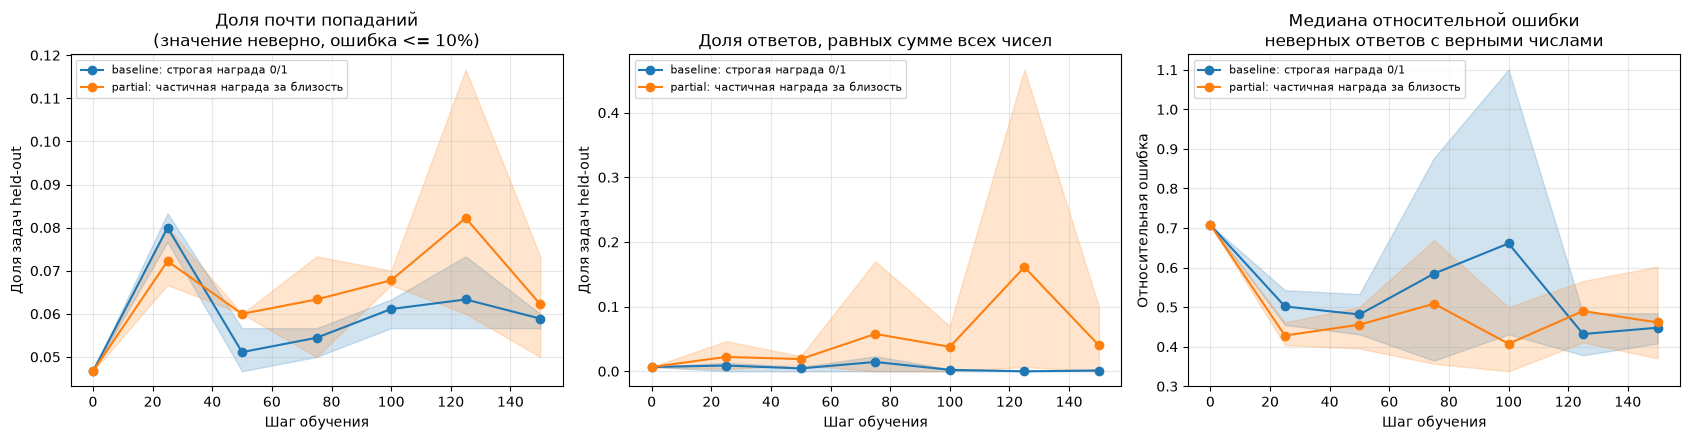

In [24]:
# Блок: признаки reward hacking на held-out по шагам обучения (заданы заранее, см. раздел 1.2)
indicator_names = {
    "near_miss_share": "Доля почти попаданий\n(значение неверно, ошибка <= 10%)",
    "sum_of_numbers_share": "Доля ответов, равных сумме всех чисел",
    "median_relative_error_wrong_value": "Медиана относительной ошибки\nневерных ответов с верными числами",
}
indicator_tables = {}
for condition in CONDITIONS:
    indicator_tables[condition] = []
    for run_index, run_name in enumerate(runs[condition]):
        rows = []
        for step in heldout_curves[condition][run_index]["step"]:
            answers = analysis.load_answers(run_name, int(step), "heldout")
            indicators = analysis.hacking_indicators(answers)
            indicators["step"] = int(step)
            rows.append(indicators)
        indicator_tables[condition].append(pd.DataFrame(rows))

figure, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for index, (column, title) in enumerate(indicator_names.items()):
    for condition in CONDITIONS:
        tables = indicator_tables[condition]
        if len(tables) == 0:
            continue
        stats = analysis.mean_and_spread_by_step(tables, column)
        axes[index].plot(stats["step"], stats["mean"], marker="o", color=CONDITION_COLORS[condition],
                         label=CONDITION_LABELS[condition])
        axes[index].fill_between(stats["step"], stats["min"], stats["max"], color=CONDITION_COLORS[condition], alpha=0.2)
    axes[index].set_title(title)
    axes[index].set_xlabel("Шаг обучения")
    axes[index].set_ylabel("Доля задач held-out" if index < 2 else "Относительная ошибка")
    axes[index].grid(alpha=0.3)
    axes[index].legend(fontsize=8)
plt.tight_layout()
plt.show()

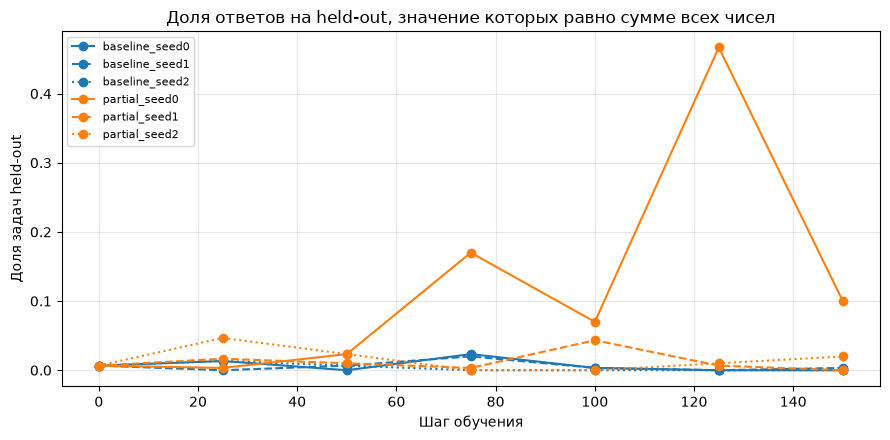

Доля ответов = сумма всех чисел, %:
        Запуск  шаг 0  шаг 25  шаг 50  шаг 75  шаг 100  шаг 125  шаг 150
baseline_seed0    0.7     1.3     0.0     2.3      0.3      0.0      0.0
baseline_seed1    0.7     0.0     0.7     2.0      0.3      0.0      0.3
baseline_seed2    0.7     1.3     0.7     0.0      0.0      0.0      0.0
 partial_seed0    0.7     0.3     2.3    17.0      7.0     46.7     10.0
 partial_seed1    0.7     1.7     1.0     0.3      4.3      0.7      0.0
 partial_seed2    0.7     4.7     2.3     0.0      0.0      1.0      2.0


In [25]:
# Блок: доля ответов "сумма всех чисел" на held-out по шагам для каждого seed
figure, axis = plt.subplots(figsize=(9, 4.5))
for condition in CONDITIONS:
    for run_index, run_name in enumerate(runs[condition]):
        table = indicator_tables[condition][run_index]
        axis.plot(table["step"], table["sum_of_numbers_share"], marker="o", linestyle=SEED_LINE_STYLES[run_index],
                  color=CONDITION_COLORS[condition], label=run_name)
axis.set_title("Доля ответов на held-out, значение которых равно сумме всех чисел")
axis.set_xlabel("Шаг обучения")
axis.set_ylabel("Доля задач held-out")
axis.grid(alpha=0.3)
axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

rows = []
for condition in CONDITIONS:
    for run_index, run_name in enumerate(runs[condition]):
        table = indicator_tables[condition][run_index]
        row = {"Запуск": run_name}
        for _, point in table.iterrows():
            row["шаг " + str(int(point["step"]))] = round(100 * point["sum_of_numbers_share"], 1)
        rows.append(row)
print("Доля ответов = сумма всех чисел, %:")
print(pd.DataFrame(rows).to_string(index=False))

### Эпизод reward hacking в partial_seed0

На шаге 125 точность partial_seed0 упала с 54.3% до 20.3%, а почти половина ответов стала суммой всех трёх чисел.
Совпадение 61 верного ответа с базовой моделью случайное: с ответами базы дословно совпадают только 9 из 300 ответов
шага 125, а ошибок "не те числа" всего 3 (у базы 65). То есть адаптер работал, и модель вела себя иначе, чем база.
Ниже - что стало с задачами, которые модель решала на шаге 100, и как эпизод выглядит в метриках обучения.

In [26]:
# Блок: что стало на шагах 125 и 150 с задачами, которые partial_seed0 решал на шаге 100
from fractions import Fraction

episode_run = "partial_seed0"
answers_100 = analysis.load_answers(episode_run, 100, "heldout")
answers_125 = analysis.load_answers(episode_run, 125, "heldout")
answers_150 = analysis.load_answers(episode_run, 150, "heldout")


def is_sum_of_numbers(record):
    if record["value"] is None:
        return False
    return Fraction(record["value"]) == sum(record["numbers"])


solved_100 = 0
sum_125 = 0
correct_again_150 = 0
rows = []
for record_100, record_125, record_150 in zip(answers_100, answers_125, answers_150):
    if record_100["status"] != "correct":
        continue
    solved_100 += 1
    if is_sum_of_numbers(record_125):
        sum_125 += 1
        if record_150["status"] == "correct":
            correct_again_150 += 1
        if len(rows) < 10:
            rows.append({
                "Числа": record_100["numbers"],
                "Цель": record_100["target"],
                "Шаг 100 (верно)": record_100["expression"],
                "Шаг 125": str(record_125["expression"]) + " = " + str(record_125["value"]),
                "Шаг 150": str(record_150["expression"]) + " (" + record_150["status"] + ")",
            })
print("Задач, решённых на шаге 100:", solved_100)
print("Из них на шаге 125 ответ = сумма всех чисел:", sum_125)
print("Из этих задач снова решены на шаге 150:", correct_again_150)
pd.DataFrame(rows)

Задач, решённых на шаге 100: 163
Из них на шаге 125 ответ = сумма всех чисел: 81
Из этих задач снова решены на шаге 150: 70


,Числа,Цель,Шаг 100 (верно),Шаг 125,Шаг 150
0,"[30, 78, 7]",101,78 + 30 - 7,78 + 30 + 7 = 115,78 + 30 - 7 (correct)
1,"[1, 89, 96]",184,96 + 89 - 1,96 + 89 + 1 = 186,96 + 89 - 1 (correct)
2,"[90, 25, 36]",101,90 + 36 - 25,90 + 36 + 25 = 151,90 + 36 - 25 (correct)
3,"[88, 23, 4]",107,88 + 23 - 4,88 + 23 + 4 = 115,88 + 23 - 4 (correct)
4,"[59, 13, 70]",116,70 + 59 - 13,70 + 59 + 13 = 142,70 + 59 - 13 (correct)
5,"[82, 74, 45]",111,82 + 74 - 45,82 + 74 + 45 = 201,82 + 74 - 45 (correct)
6,"[92, 91, 86]",97,92 + 91 - 86,92 + 91 + 86 = 269,92 + 91 - 86 (correct)
7,"[52, 66, 11]",107,66 + 52 - 11,66 + 52 + 11 = 129,66 + 52 - 11 (correct)
8,"[68, 93, 94]",119,94 + 93 - 68,94 + 93 + 68 = 255,94 + 93 - 68 (correct)
9,"[23, 92, 10]",79,92 - 23 + 10,92 + 23 + 10 = 125,92 - 23 + 10 (correct)


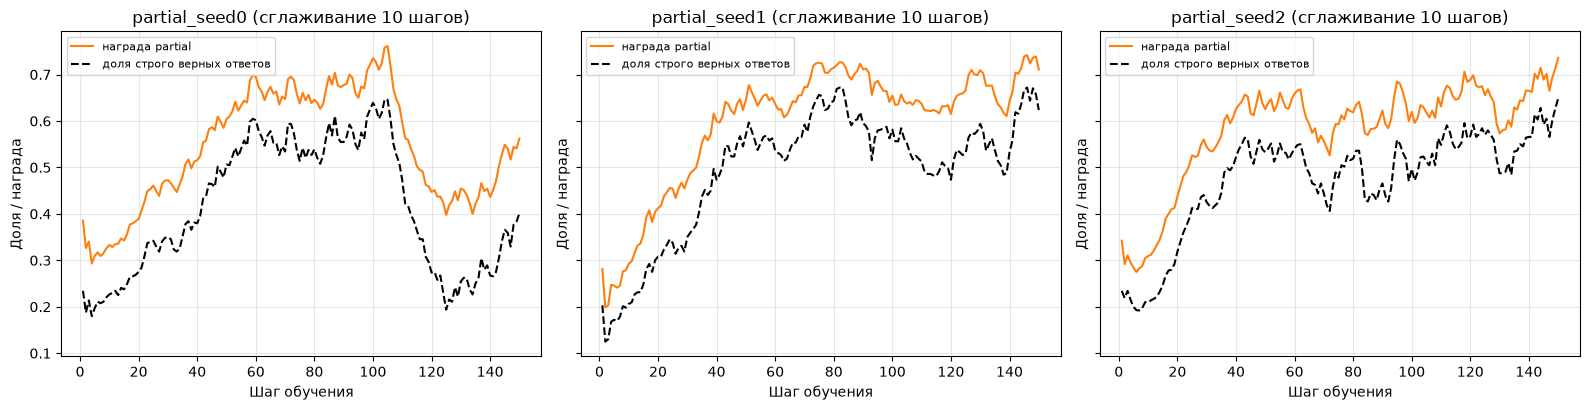

Средние по участкам шагов (обучающие ответы):
baseline_seed0 | шаги 51 - 100 | награда: 0.503 | доля верных: 0.503 | награда за неверные: 0.0
baseline_seed0 | шаги 101 - 150 | награда: 0.602 | доля верных: 0.602 | награда за неверные: 0.0
baseline_seed1 | шаги 51 - 100 | награда: 0.563 | доля верных: 0.563 | награда за неверные: 0.0
baseline_seed1 | шаги 101 - 150 | награда: 0.552 | доля верных: 0.552 | награда за неверные: 0.0
baseline_seed2 | шаги 51 - 100 | награда: 0.496 | доля верных: 0.496 | награда за неверные: 0.0
baseline_seed2 | шаги 101 - 150 | награда: 0.542 | доля верных: 0.542 | награда за неверные: 0.0
partial_seed0 | шаги 51 - 100 | награда: 0.68 | доля верных: 0.574 | награда за неверные: 0.106
partial_seed0 | шаги 101 - 150 | награда: 0.499 | доля верных: 0.334 | награда за неверные: 0.166
partial_seed1 | шаги 51 - 100 | награда: 0.678 | доля верных: 0.59 | награда за неверные: 0.088
partial_seed1 | шаги 101 - 150 | награда: 0.663 | доля верных: 0.547 | награда за нев

In [27]:
# Блок: награда partial против доли строго верных ответов на обучающих ответах (каждый запуск partial)
# Разница между линиями - награда, которую модель получила за неверные ответы (частичная награда).
figure, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for run_index, run_name in enumerate(runs["partial"]):
    table = train_logs["partial"][run_index]
    reward_smooth = analysis.rolling_mean(table, "reward", SMOOTH_WINDOW)
    correct_smooth = analysis.rolling_mean(table, "status/correct", SMOOTH_WINDOW)
    axis = axes[run_index]
    axis.plot(reward_smooth["step"], reward_smooth["reward"], color="tab:orange", label="награда partial")
    axis.plot(correct_smooth["step"], correct_smooth["status/correct"], color="black", linestyle="--",
              label="доля строго верных ответов")
    axis.set_title(run_name + " (сглаживание 10 шагов)")
    axis.set_xlabel("Шаг обучения")
    axis.set_ylabel("Доля / награда")
    axis.grid(alpha=0.3)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()

print("Средние по участкам шагов (обучающие ответы):")
for condition in CONDITIONS:
    for run_index, run_name in enumerate(runs[condition]):
        table = train_logs[condition][run_index]
        for first_step, last_step in [(51, 100), (101, 150)]:
            part = table[(table["step"] >= first_step) & (table["step"] <= last_step)]
            reward_mean = part["reward"].mean()
            correct_mean = part["status/correct"].mean()
            print(run_name, "| шаги", first_step, "-", last_step, "| награда:", round(reward_mean, 3),
                  "| доля верных:", round(correct_mean, 3), "| награда за неверные:", round(reward_mean - correct_mean, 3))

In [28]:
# Блок: сколько частичной награды получает шаблон "сумма всех чисел" на обучающих задачах
# Сумма никогда не бывает верным ответом (такие цели исключены при генерации данных), но получает частичную награду.
from src.reward import partial_reward_from_check

train_tasks = load_jsonl(config.TRAIN_PATH)
sum_rewards = []
for task in train_tasks:
    expression = " + ".join(str(number) for number in task["numbers"])
    check = check_answer("<answer>" + expression + "</answer>", task["numbers"], task["target"])
    sum_rewards.append(partial_reward_from_check(check, task["target"]))

positive_rewards = []
for value in sum_rewards:
    if value > 0:
        positive_rewards.append(value)
print("Задач в train:", len(train_tasks))
print("Доля задач, где сумма всех чисел получает частичную награду > 0:", round(len(positive_rewards) / len(train_tasks), 3))
print("Средняя награда суммы там, где она > 0:", round(sum(positive_rewards) / len(positive_rewards), 3))
print("Средняя награда суммы по всем задачам:", round(sum(sum_rewards) / len(sum_rewards), 3))

Задач в train: 3985
Доля задач, где сумма всех чисел получает частичную награду > 0: 0.433
Средняя награда суммы там, где она > 0: 0.295
Средняя награда суммы по всем задачам: 0.128


In [29]:
# Блок: какие задачи решает модель - хватает ли для решения сложения и вычитания
# Перебираем все расстановки знаков + и - перед тремя числами (хотя бы один знак +).
# Если какая-то даёт цель, задачу можно решить без умножения и деления.
import itertools

heldout_tasks = load_jsonl(config.HELDOUT_PATH)


def solvable_with_plus_minus(numbers, target):
    for signs in itertools.product([1, -1], repeat=len(numbers)):
        if -1 in signs and 1 not in signs:
            continue
        total = 0
        for sign, number in zip(signs, numbers):
            total += sign * number
        if total == target:
            return True
    return False


plus_minus_flags = []
for task in heldout_tasks:
    plus_minus_flags.append(solvable_with_plus_minus(task["numbers"], task["target"]))
plus_minus_total = sum(plus_minus_flags)
other_total = len(heldout_tasks) - plus_minus_total
print("Задач held-out:", len(heldout_tasks), "| решаемых только сложением и вычитанием:", plus_minus_total,
      "| требующих умножения или деления:", other_total)

rows = []
models = {"база (до обучения)": base_answers}
for run_name, answers in final_answers.items():
    models[run_name] = answers
for model_name, answers in models.items():
    solved_plus_minus = 0
    solved_other = 0
    with_mul_div = 0
    for record, is_plus_minus in zip(answers, plus_minus_flags):
        if record["status"] != "correct":
            continue
        if is_plus_minus:
            solved_plus_minus += 1
        else:
            solved_other += 1
        if "*" in record["expression"] or "/" in record["expression"]:
            with_mul_div += 1
    rows.append({
        "Модель": model_name,
        "Решено из задач на + и -": str(solved_plus_minus) + " из " + str(plus_minus_total),
        "Решено из задач с * или /": str(solved_other) + " из " + str(other_total),
        "Верных ответов с * или /": with_mul_div,
    })
pd.DataFrame(rows)

Задач held-out: 300 | решаемых только сложением и вычитанием: 248 | требующих умножения или деления: 52


,Модель,Решено из задач на + и -,Решено из задач с * или /,Верных ответов с * или /
0,база (до обучения),58 из 248,3 из 52,3
1,baseline_seed0,192 из 248,0 из 52,0
2,baseline_seed1,186 из 248,0 из 52,0
3,baseline_seed2,153 из 248,2 из 52,2
4,partial_seed0,170 из 248,0 из 52,0
5,partial_seed1,186 из 248,2 из 52,2
6,partial_seed2,171 из 248,2 из 52,2


In [30]:
# Блок: примеры ошибочных ответов итоговых моделей (по 2 примера на каждый тип ошибки)
for run_name, answers in final_answers.items():
    print("=" * 100)
    print(run_name)
    shown = {}
    for record in answers:
        status = record["status"]
        if status == "correct":
            continue
        if shown.get(status, 0) >= 2:
            continue
        shown[status] = shown.get(status, 0) + 1
        print(" ", status, "| числа", record["numbers"], "-> цель", record["target"],
              "| ответ:", record["completion"].strip(), "| значение:", record["value"])

baseline_seed0
  wrong_value | числа [13, 51, 44] -> цель 91 | ответ: <answer>51 + 44 - 13</answer> | значение: 82
  wrong_value | числа [44, 29, 46] -> цель 27 | ответ: <answer>46 - 44 + 29</answer> | значение: 31
  wrong_numbers | числа [12, 6, 30] -> цель 192 | ответ: <answer>30 + 30 * 12</answer> | значение: None
baseline_seed1
  wrong_value | числа [13, 51, 44] -> цель 91 | ответ: <answer>51 + 44 - 13</answer> | значение: 82
  wrong_value | числа [42, 18, 21] -> цель 49 | ответ: <answer>42 + 21 - 18</answer> | значение: 45
  wrong_numbers | числа [50, 4, 8] -> цель 46 | ответ: <answer>50 - 48</answer> | значение: None
  wrong_numbers | числа [76, 85, 70] -> цель 61 | ответ: <answer>85 - 80 + 76 - 70</answer> | значение: None
baseline_seed2
  wrong_value | числа [30, 78, 7] -> цель 101 | ответ: <answer>78 - 30 + 7</answer> | значение: 55
  wrong_value | числа [13, 51, 44] -> цель 91 | ответ: <answer>51 + 44 - 13</answer> | значение: 82
  wrong_numbers | числа [1, 24, 84] -> цель 10

In [31]:
# Блок: поиск reward hacking - ответы, равные сумме всех чисел, и почти попадания у итоговых моделей
from fractions import Fraction

for run_name, answers in final_answers.items():
    sum_examples = []
    near_examples = []
    for record in answers:
        if record["value"] is None:
            continue
        value = Fraction(record["value"])
        if value == sum(record["numbers"]):
            sum_examples.append(record)
        if record["status"] == "wrong_value" and abs(value - record["target"]) / record["target"] <= 0.10:
            near_examples.append(record)
    print("=" * 100)
    print(run_name, "| ответов = сумма чисел:", len(sum_examples), "| почти попаданий:", len(near_examples))
    for record in sum_examples[:3]:
        print("   сумма:", record["numbers"], "-> цель", record["target"], "| ответ:", record["completion"].strip())
    for record in near_examples[:3]:
        print("   почти:", record["numbers"], "-> цель", record["target"], "| ответ:", record["completion"].strip(),
              "| значение:", record["value"])

baseline_seed0 | ответов = сумма чисел: 0 | почти попаданий: 18
   почти: [13, 51, 44] -> цель 91 | ответ: <answer>51 + 44 - 13</answer> | значение: 82
   почти: [42, 18, 21] -> цель 49 | ответ: <answer>42 + 21 - 18</answer> | значение: 45
   почти: [67, 57, 68] -> цель 56 | ответ: <answer>68 - 67 + 57</answer> | значение: 58
baseline_seed1 | ответов = сумма чисел: 1 | почти попаданий: 17
   сумма: [45, 51, 7] -> цель 89 | ответ: <answer>51 + 7 + 45</answer>
   почти: [13, 51, 44] -> цель 91 | ответ: <answer>51 + 44 - 13</answer> | значение: 82
   почти: [42, 18, 21] -> цель 49 | ответ: <answer>42 + 21 - 18</answer> | значение: 45
   почти: [67, 57, 68] -> цель 56 | ответ: <answer>68 - 67 + 57</answer> | значение: 58
baseline_seed2 | ответов = сумма чисел: 0 | почти попаданий: 18
   почти: [13, 51, 44] -> цель 91 | ответ: <answer>51 + 44 - 13</answer> | значение: 82
   почти: [42, 18, 21] -> цель 49 | ответ: <answer>42 + 21 - 18</answer> | значение: 45
   почти: [67, 57, 68] -> цель 56

## 11. Выводы

### 11.1. Baseline: работает ли GRPO со строгой наградой

Да. За 150 шагов строгая точность на held-out выросла с 20.3% до 59.2% (среднее по 3 seed, от 51.7% до 64.0%).
Прирост есть в каждом seed, и он намного больше шума одной оценки (стандартная ошибка доли на 300 задачах
около 2.8 п.п. при точности 60%). Из 300 задач обученные модели исправили 121-147 и сломали 9-27 (раздел 9).

Что изменилось в поведении модели:
- Почти исчезла ошибка "не те числа": у базы 65 из 300, у обученных моделей 1-5. Это правило модель выучила
  быстрее всего, основной спад - за первые 25 шагов (график статусов в разделе 7).
- Почти все оставшиеся ошибки - неверное значение при верных числах. Частый случай - перепутан знак или порядок
  вычитания (например, `51 + 44 - 13 = 82` при цели 91).
- Модель решает почти только задачи, где хватает сложения и вычитания. Таких в held-out 248 из 300.
  Из них обученные модели решают от 62% до 77% (база - 23%), а из 52 задач, где нужны умножение или деление,
  от 0 до 2 (база - 3). По сути GRPO научил модель подбирать знаки `+` и `-` между тремя числами.
- Длина ответа не изменилась (16.5-16.7 токена): модель отвечает одним выражением в тегах, и обучение это не сломало.
- KL к исходной модели вырос до 0.1-0.15 и дальше не рос. Энтропия упала с 0.16 до 0.01-0.02:
  к концу обучения модель почти детерминирована.
- Основной прирост приходится на первые 50 шагов. Дальше доля групп без сигнала растёт до 0.77-0.90:
  большинство групп целиком верные, сигнала для GRPO становится меньше, и рост замедляется.

### 11.2. Ответ на исследовательский вопрос

Вопрос: помогает ли частичная награда за близость значения к цели, или модель начинает оптимизировать
"почти попадания" в ущерб точным ответам?

| Строгая точность на held-out, шаг 150 | baseline | partial |
|---|---|---|
| seed 0 / 1 / 2 | 64.0 / 62.0 / 51.7% | 56.7 / 62.7 / 57.7% |
| среднее по 3 seed | 59.2% | 59.0% |
| std по seed | 5.4 п.п. | 2.6 п.п. |
| partial минус baseline по парам seed | | -7.3 / +0.7 / +6.0 п.п. |

**По правилу вывода, заданному до запусков, заметной разницы нет**: разница средних (0.2 п.п.) намного меньше
разброса между seed, а знак разницы в трёх парах seed разный. Частичная награда итоговую точность не улучшила,
но и в среднем не ухудшила.

Гипотеза по частям:
1. **Меньше групп без сигнала - подтвердилось только в начале обучения.** На шагах 1-25 таких групп у partial
   9-13%, у baseline 32-35%. На шаге 25 partial немного впереди (40.8% против 37.0% в среднем), но к шагу 50 условия
   сравниваются. Дальше доли групп без сигнала почти одинаковые (0.70-0.86 против 0.77-0.90): когда большинство
   групп целиком верные, частичная награда в них ничего не меняет.
2. **Строгая точность не выше, чем у baseline - подтвердилось.**
3. **Лазейка "сложить все числа" - подтвердилась, но не в каждом запуске.** В partial_seed0 доля "сумм" на held-out
   была 17% уже на шаге 75, а на шаге 125 суммой всех трёх чисел были 46.7% ответов, и точность упала с 54.3%
   до 20.3%. Из 163 задач, решённых на шаге 100, 81 на шаге 125 превратилась в сумму (раздел 10). К шагу 150 модель
   вернулась к 56.7% (70 из этих 81 задач снова решены), но "сумм" осталось 10% (у базы 0.7%). В partial_seed1
   и partial_seed2 доля "сумм" не превышала 4.3% и 4.7%, в baseline - 2.3% ни в одной точке. При этом "почти попаданий" (ошибка не больше 10%) не стало больше ни в одном запуске (5-7%): модель
   воспользовалась не точными почти попаданиями, а простым шаблоном.

**Итог.** В этой постановке частичная награда за близость не помогает: средняя точность та же, а в одном запуске
из трёх модель на время переключилась на лазейку и потеряла больше половины решённых задач. Строгая бинарная
награда из задания оказалась не хуже и надёжнее.

### 11.3. Как это объяснить

- Сумма всех чисел никогда не бывает верным ответом, но в 43% обучающих задач получает частичную награду
  (в среднем около 0.3 там, где она есть). Выражение всегда соблюдает правила, поэтому никогда не получает 0
  за нарушение. Это дешёвый и "безопасный" ответ, когда модель не может найти решение.
- Сумма к тому же очень близка к привычным ответам модели. Многие верные решения в этих данных имеют вид
  `a + b - c`, и сумма получается заменой одного минуса на плюс: `78 + 30 - 7` превращалось в `78 + 30 + 7`
  (таблица эпизода в разделе 10). Поэтому сдвиг к шаблону требует совсем небольшого изменения политики.
- В GRPO преимущество делится на std награды внутри группы. В группе, где все 8 ответов неверные, разница
  0.3 против 0.1 после нормировки даёт такое же по величине преимущество, как 1 против 0 в обычной группе.
  Поэтому слабый сигнал близости толкает модель так же сильно, как сигнал правильности. Это наше объяснение,
  отдельно мы его не проверяли.
- Эпизод в partial_seed0 - reward hacking по поведению (шаблон получает награду, не решая задачу), но не в смысле
  "награда растёт, а точность падает": средняя награда на шагах 101-150 тоже снизилась (0.68 на шагах 51-100,
  0.50 на шагах 101-150). Одновременно выросла доля награды за неверные ответы (с 0.11 до 0.17). Такой сдвиг
  виден по логам обучения - по расхождению награды и доли строго верных ответов, без использования held-out.
  KL во время эпизода тоже выше: скользящая медиана около 0.15-0.16 против 0.10-0.11 у baseline на шагах 120-135.
- Энтропия у partial падала быстрее, чем у baseline (шаги 20-50, раздел 7): плотный сигнал быстрее делает политику
  детерминированной. Возможно, поэтому переключение на шаблон было резким, но по 3 seed это утверждать нельзя.

### 11.4. Альтернативные объяснения и ограничения

- **Шум seed.** Разброс между seed у baseline (5.4 п.п.) больше любой правдоподобной разницы условий.
  Чтобы увидеть разницу в 2-3 п.п., нужно заметно больше seed.
- **Шум оценки.** Стандартная ошибка одной оценки на 300 задачах около 2.8 п.п.
- **Эпизод срыва случился в 1 запуске из 3.** На других seed его можно не увидеть или увидеть чаще. Итог шага 150
  зависит от того, в какой фазе эпизода оказалась модель: остановись обучение на шаге 125, partial_seed0 дал бы 20.3%,
  и вывод по правилу был бы другим. Это довод против того, чтобы судить только по последней точке.
- **Прирост получен почти только на задачах, решаемых сложением и вычитанием** (82.7% held-out). Задачи
  с умножением и делением модель не решает ни до, ни после обучения, поэтому вывод относится в первую очередь
  к этой части задач. Сравнение условий на задачах с `*` и `/` по сути не проведено.
- **Одна форма частичной награды** (линейная близость, максимум 0.5). Другая форма или меньший максимум могут вести
  себя иначе.
- **Ограниченная постановка:** 150 шагов, одна модель (0.6B), одна сложность (3 числа), фиксированные lr и KL beta,
  greedy-оценка. Гиперпараметры подбирались в пилоте на строгой награде и для partial отдельно не настраивались.

### 11.5. Что проверить дальше

1. Закрыть лазейку и повторить сравнение на тех же 3 seed. Варианты: давать частичную награду только в группах,
   где нет ни одного верного ответа, уменьшать её вес по ходу обучения или нормировать преимущество по всему батчу,
   а не по группе. Запрет конкретного шаблона "сумма всех чисел" - заплатка: модель может найти следующий.
2. Больше seed и более длинное обучение, чтобы оценить, как часто случаются такие эпизоды.
3. Детектор reward hacking по логам обучения: остановка или откат, когда награда и доля строго верных ответов
   начинают расходиться.
4. Задачи, где нужны умножение или деление: обучение на выборке, где их больше, и отдельная оценка на них.
   Сейчас модель такие задачи не решает.
5. Проверить обученные модели на задачах с 4 числами (без дообучения): переносится ли выученное правило
   "каждое число ровно один раз" на более сложные задачи.